# ETL-12 · Comparativo 2021 × 2022 × 2023

- **Etapa:** ETL-12, Comparativo entre anos
- **Responsável:** Samuel
- **Issue:** #14
- **Entrada:** `docs/perfil/perfil_2021.md`, `perfil_2022.md`, `perfil_2023.md`, `corrompidos_2021.csv`, `corrompidos_2022.csv`, `corrompidos_2023.csv` (saídas das ETL-07, 08 e 09) e três resumos do `01_bruto.parquet` em `docs/perfil/resumos/` (`valores_por_ano.csv`, `mensal.csv`, `por_dimensao.csv`)
- **Saída:** `docs/perfil/comparativo_anos.md` e `docs/evidencias/grau_instrucao_36_meses.png`

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raiz do repositório: sobe de pasta em pasta até achar a pasta .git
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())

PERFIS     = RAIZ / "docs" / "perfil"
EVIDENCIAS = RAIZ / "docs" / "evidencias"
RESUMOS    = RAIZ / "docs" / "perfil" / "resumos"
EVIDENCIAS.mkdir(parents=True, exist_ok=True)
RESUMOS.mkdir(parents=True, exist_ok=True)

ANOS = [2021, 2022, 2023]
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

## 2. Ler os três perfis

Os perfis das ETL-07, 08 e 09 foram gerados pela mesma função `perfil()`, com as mesmas 10 perguntas, na mesma ordem. Em vez de rodar tudo de novo nas 806.977 linhas, este notebook **lê as tabelas dos três `.md`** e compara os resultados lado a lado. O que os perfis não trazem (quais categorias existem em cada ano, o comportamento mês a mês e por região) vem dos três resumos da seção 3.

In [2]:
TEXTO = {"valor", "coluna", "motivo", "mês", "métrica"}   # colunas que ficam como texto

def numero_br(s: str):
    """'1.234' -> 1234 | '12,5' -> 12.5 | '—' -> NaN | outro texto fica como está."""
    s = s.strip()
    if s == "—":
        return float("nan")
    if s.lstrip("-").replace(".", "").isdigit() and ("." not in s or len(s.split(".")[-1]) == 3):
        return int(s.replace(".", ""))
    try:
        return float(s.replace(".", "").replace(",", "."))
    except ValueError:
        return s

def ler_tabelas(caminho: Path) -> dict:
    """Lê todas as tabelas de um perfil .md. Devolve {título da seção: [DataFrame, ...]}."""
    grupos, secao, atual = {}, None, []

    def fechar():
        nonlocal atual
        if atual:
            cab = [c.strip() for c in atual[0].strip().strip("|").split("|")]
            linhas = [[c.strip() for c in ln.strip().strip("|").split("|")] for ln in atual[2:]]
            df = pd.DataFrame(linhas, columns=cab)
            texto = TEXTO - {"valor"} if "métrica" in cab else TEXTO
            for c in cab:
                if c not in texto:
                    df[c] = df[c].map(numero_br)
            grupos.setdefault(secao, []).append(df)
            atual = []

    for ln in caminho.read_text(encoding="utf-8").splitlines():
        if ln.startswith("#"):
            fechar()
            secao = ln.lstrip("#").strip()
        elif ln.startswith("|"):
            atual.append(ln)
        else:
            fechar()
    fechar()
    return grupos

T = {a: ler_tabelas(PERFIS / f"perfil_{a}.md") for a in ANOS}

def tabela(ano: int, prefixo: str, i: int = 0) -> pd.DataFrame:
    """i-ésima tabela da primeira seção do perfil `ano` cujo título começa com `prefixo`."""
    chave = next(k for k in T[ano] if k.startswith(prefixo))
    return T[ano][chave][i]

print("seções com tabela em cada perfil:", {a: len(T[a]) for a in ANOS})

seções com tabela em cada perfil: {2021: 27, 2022: 27, 2023: 27}


## 3. Resumos do `01_bruto.parquet`

Os perfis só dizem **quantos** valores distintos há, não **quais**, e não abrem os números por mês ou por região. Três resumos pequenos cobrem isso:

- `valores_por_ano.csv`: cada valor de `municipio`, `nacionalidade` e `profissao`, por ano, com o número de linhas;
- `mensal.csv`: uma linha por mês, com o número de linhas, de `NAO DISPONIVEL` em `local_via` e em `sexo` e de `grau_de_instrucao` preenchido;
- `por_dimensao.csv`: os mesmos números por região administrativa, tipo de via e tipo de vítima.

A célula abaixo os gera a partir de `data/intermediarios/01_bruto.parquet`, se ainda não existirem em `docs/perfil/resumos/`. Se já existem (versionados no repositório), só os reaproveita.

In [3]:
BRUTO = RAIZ / "data" / "intermediarios" / "01_bruto.parquet"
ARQUIVOS_RESUMO = ["valores_por_ano.csv", "mensal.csv", "por_dimensao.csv"]
faltam = [a for a in ARQUIVOS_RESUMO if not (RESUMOS / a).exists()]

if not faltam:
    print("Resumos já existem em docs/perfil/resumos/:", ARQUIVOS_RESUMO)
elif not BRUTO.exists():
    raise FileNotFoundError(f"Faltam {faltam} em docs/perfil/resumos/ e não achei o 01_bruto.parquet para gerá-los.")
else:
    colunas = ["municipio", "regiao_administrativa", "tipo_via", "tipo_de_vitima", "nacionalidade",
               "profissao", "local_via", "sexo", "grau_de_instrucao"]
    df = pd.read_parquet(BRUTO, columns=["arquivo_origem"] + colunas)    # lê só as colunas necessárias
    ext = df["arquivo_origem"].str.extract(r"pessoas_(\d{2})-(\d{4})")
    df["mes"], df["ano"] = ext[0], ext[1]
    df["nacionalidade"] = df["nacionalidade"].str.strip()
    print(len(df), "linhas lidas (esperado: 806977)")

    nd = lambda s: s.str.strip().str.upper().eq("NAO DISPONIVEL")
    df["local_via_nd"] = nd(df["local_via"])
    df["sexo_nd"] = nd(df["sexo"])
    df["grau_ok"] = df["grau_de_instrucao"].notna()
    soma = dict(linhas=("ano", "size"), local_via_nd=("local_via_nd", "sum"),
                sexo_nd=("sexo_nd", "sum"), grau_preenchido=("grau_ok", "sum"))

    longos = []
    for col in ["municipio", "nacionalidade", "profissao"]:
        t = df.groupby(["ano", col]).size().rename("n").reset_index().rename(columns={col: "valor"})
        t.insert(0, "coluna", col)
        longos.append(t)
    pd.concat(longos).to_csv(RESUMOS / "valores_por_ano.csv", index=False)

    df.groupby(["ano", "mes"]).agg(**soma).reset_index().to_csv(RESUMOS / "mensal.csv", index=False)

    quadros = []
    for dim in ["regiao_administrativa", "tipo_via", "tipo_de_vitima"]:
        t = df.groupby(["ano", dim]).agg(**soma).reset_index().rename(columns={dim: "valor"})
        t.insert(0, "dimensao", dim)
        quadros.append(t)
    pd.concat(quadros).to_csv(RESUMOS / "por_dimensao.csv", index=False)
    print("resumos gerados em docs/perfil/resumos/")

806977 linhas lidas (esperado: 806977)
resumos gerados em docs/perfil/resumos/


In [4]:
valores   = pd.read_csv(RESUMOS / "valores_por_ano.csv", dtype={"valor": str})
mensal_res = pd.read_csv(RESUMOS / "mensal.csv", dtype={"mes": str})
dimensao  = pd.read_csv(RESUMOS / "por_dimensao.csv", dtype={"valor": str})

print("valores_por_ano:", valores.shape, "| mensal:", mensal_res.shape, "| por_dimensao:", dimensao.shape)
print("linhas somadas em mensal.csv:", mensal_res["linhas"].sum(), "| confere com a extração (806977):",
      mensal_res["linhas"].sum() == 806977)

valores_por_ano: (3899, 4) | mensal: (36, 6) | por_dimensao: (69, 7)
linhas somadas em mensal.csv: 806977 | confere com a extração (806977): True


## 4. Achado 1 · Volume e estrutura

Linhas, sinistros, óbitos e as checagens de integridade (colunas, duplicatas, mês do arquivo), lado a lado.

In [5]:
def metricas(ano: int, prefixo: str) -> pd.Series:
    return tabela(ano, prefixo).set_index("métrica")["valor"]

resumo = pd.DataFrame.from_dict({
    a: {
        "linhas": metricas(a, "1.")["Linhas"],
        "sinistros": metricas(a, "1.")["Sinistros distintos (id_sinistro)"],
        "pessoas por sinistro (média)": metricas(a, "1.")["Pessoas por sinistro: média"],
        "óbitos": metricas(a, "6.")["Óbitos (data_obito preenchida)"],
        "% óbitos": metricas(a, "6.")["% do total de linhas"],
        "idade máxima": metricas(a, "9.")["Máximo observado"],
    } for a in ANOS
}, orient="index").astype({"linhas": int, "sinistros": int, "óbitos": int})
resumo

,linhas,sinistros,pessoas por sinistro (média),óbitos,% óbitos,idade máxima
2021,260886,128207,2.03,4858,1.86,102.0
2022,266128,132358,2.01,5445,2.05,99.0
2023,279963,142130,1.97,5490,1.96,100.0


In [6]:
l = resumo["linhas"]
print(f"linhas 2021→2022: {(l[2022] / l[2021] - 1) * 100:+.1f}% | 2022→2023: {(l[2023] / l[2022] - 1) * 100:+.1f}%")
print(f"sinistros 2021→2022: {(resumo.loc[2022, 'sinistros'] / resumo.loc[2021, 'sinistros'] - 1) * 100:+.1f}% | "
      f"2022→2023: {(resumo.loc[2023, 'sinistros'] / resumo.loc[2022, 'sinistros'] - 1) * 100:+.1f}%")
print("total de linhas:", l.sum(), "| confere com a extração (806977):", l.sum() == 806977)
print("total de óbitos:", resumo["óbitos"].sum(), "| confere com o plano (15793):", resumo["óbitos"].sum() == 15793)

colunas = {a: list(tabela(a, "2.")["coluna"]) for a in ANOS}
print(f"mesmas {len(colunas[2021])} colunas, na mesma ordem, nos 3 anos:", colunas[2021] == colunas[2022] == colunas[2023])

checagens = pd.concat([tabela(a, "7.").set_index("métrica")["valor"].rename(a) for a in ANOS], axis=1)
checagens.loc["Linhas com mês divergente (pergunta 8)"] = [metricas(a, "8.")["Linhas com mês divergente"] for a in ANOS]
checagens.loc["Linhas fora de 0 a 110 anos (pergunta 9)"] = [metricas(a, "9.")["Fora de 0 a 110"] for a in ANOS]
checagens = checagens.astype(int)
checagens

linhas 2021→2022: +2.0% | 2022→2023: +5.2%
sinistros 2021→2022: +3.2% | 2022→2023: +7.4%
total de linhas: 806977 | confere com a extração (806977): True
total de óbitos: 15793 | confere com o plano (15793): True
mesmas 32 colunas, na mesma ordem, nos 3 anos: True


,2021,2022,2023
métrica,,,
id_pessoa nulo,0,0,0
id_pessoa que aparece mais de uma vez,0,0,0
Linhas com id_pessoa repetido,0,0,0
Linhas excedentes por id_pessoa,0,0,0
"Linhas 100% idênticas (excedentes, sem as colunas de rastreio)",0,0,0
Linhas com mês divergente (pergunta 8),0,0,0
Linhas fora de 0 a 110 anos (pergunta 9),0,0,0


## 5. Achado 2 · Categorias que surgiram ou sumiram

Quatro conferências: o número de valores distintos de cada coluna (Anexo B de cada perfil), se o **conjunto** de valores das seis colunas de domínio é o mesmo nos três anos e, com os resumos da seção 3, **quais** municípios, nacionalidades e profissões existem em cada ano.

In [7]:
distintos = pd.concat([tabela(a, "Anexo B").set_index("coluna")["valores distintos"].rename(a) for a in ANOS], axis=1)

identificadores = ["id_sinistro", "id_pessoa", "id_veiculo"]
muda = distintos[distintos.nunique(axis=1) > 1].drop(index=identificadores, errors="ignore").copy()
muda["variação 2021→2023 (%)"] = ((muda[2023] / muda[2021] - 1) * 100).round(1)
print(f"{len(muda)} colunas (fora os identificadores) mudam de número de valores distintos entre os anos:")
muda

6 colunas (fora os identificadores) mudam de número de valores distintos entre os anos:


,2021,2022,2023,variação 2021→2023 (%)
coluna,,,,
cod_ibge,644,642,645,0.2
municipio,644,642,645,0.2
idade,102,100,100,-2.0
profissao,515,588,658,27.8
nacionalidade,65,68,74,13.8
data_obito,373,374,379,1.6


In [8]:
colunas_dominio = ["gravidade_lesao", "tipo_de_vitima", "sexo", "tipo_via", "tipo_veiculo_vitima", "regiao_administrativa"]
for col in colunas_dominio:
    conj = [set(tabela(a, col, 0)["valor"]) for a in ANOS]
    print(f"{col:24s} valores por ano: {[len(c) for c in conj]} | mesmo conjunto nos 3 anos: {conj[0] == conj[1] == conj[2]}")

print()
print("linhas por ano (referência para comparar com o crescimento de profissao):",
      {a: int(resumo.loc[a, "linhas"]) for a in ANOS},
      f"-> {(resumo.loc[2023, 'linhas'] / resumo.loc[2021, 'linhas'] - 1) * 100:+.1f}% de 2021 a 2023")

gravidade_lesao          valores por ano: [5, 5, 5] | mesmo conjunto nos 3 anos: True
tipo_de_vitima           valores por ano: [4, 4, 4] | mesmo conjunto nos 3 anos: True
sexo                     valores por ano: [3, 3, 3] | mesmo conjunto nos 3 anos: True
tipo_via                 valores por ano: [3, 3, 3] | mesmo conjunto nos 3 anos: True
tipo_veiculo_vitima      valores por ano: [8, 8, 8] | mesmo conjunto nos 3 anos: True
regiao_administrativa    valores por ano: [16, 16, 16] | mesmo conjunto nos 3 anos: True

linhas por ano (referência para comparar com o crescimento de profissao): {2021: 260886, 2022: 266128, 2023: 279963} -> +7.3% de 2021 a 2023


### 5.1 Municípios

In [9]:
n_mun = valores[valores["coluna"] == "municipio"].pivot(index="valor", columns="ano", values="n").fillna(0).astype(int)
incompletos = n_mun[(n_mun == 0).any(axis=1)]
print(f"municípios na união dos três anos: {len(n_mun)} | por ano: {(n_mun > 0).sum().to_dict()}")
print("municípios ausentes em algum ano (número de linhas em cada ano):")
incompletos

municípios na união dos três anos: 645 | por ano: {2021: 644, 2022: 642, 2023: 645}
municípios ausentes em algum ano (número de linhas em cada ano):


ano,2021,2022,2023
valor,,,
ARAPEI,0,0,2
RIBEIRAO DOS INDIOS,8,0,2
URU,5,0,2


### 5.2 Nacionalidades

In [10]:
nac = valores[valores["coluna"] == "nacionalidade"].pivot(index="valor", columns="ano", values="n").fillna(0).astype(int)
nos_tres = (nac > 0).all(axis=1)
print(f"{len(nac)} valores na união; {nos_tres.sum()} aparecem nos três anos; {(~nos_tres).sum()} não aparecem.")
print("máximo de linhas, em qualquer ano, entre os que não aparecem nos três:", nac[~nos_tres].max().max())
print("\ngrafias suspeitas e a forma masculina/feminina de brasileiro:")
nac.reindex(["FÍLIPINO", "NÍGÉRIO", "KUWAÍTÍANO", "BRASILEIRO", "BRASILEIRA"])

90 valores na união; 52 aparecem nos três anos; 38 não aparecem.
máximo de linhas, em qualquer ano, entre os que não aparecem nos três: 4

grafias suspeitas e a forma masculina/feminina de brasileiro:


ano,2021,2022,2023
valor,,,
FÍLIPINO,0,1,1
NÍGÉRIO,0,1,1
KUWAÍTÍANO,0,0,1
BRASILEIRO,0,2,1
BRASILEIRA,228387,236860,241592


### 5.3 Profissões

O número de valores distintos de `profissao` sobe a cada ano. Aqui se mede quanto disso é profissão nova e quanto é só **grafia** (caixa mista, acento, pontuação). Normalizar, neste notebook, é só passar para maiúsculas, tirar acentos e pontuação e deixar espaços únicos; a padronização de verdade é da ETL-17.

In [11]:
import re
import unicodedata

def sem_acento(s: str) -> str:
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()

def normalizar(s: str) -> str:
    s = re.sub(r"[^A-Z0-9 ]", " ", sem_acento(s).upper())
    return re.sub(r"\s+", " ", s).strip()

prof = valores[valores["coluna"] == "profissao"].copy()
prof["norm"] = prof["valor"].map(normalizar)
prof["caixa_mista"] = prof["valor"] != prof["valor"].str.upper()
prof["com_acento"] = prof["valor"] != prof["valor"].map(sem_acento)

def por_ano(t: pd.DataFrame) -> pd.Series:
    return pd.Series({
        "linhas com profissao": t["n"].sum(),
        "valores distintos": t["valor"].nunique(),
        "valores distintos após normalizar": t["norm"].nunique(),
        "valores em caixa mista": int(t["caixa_mista"].sum()),
        "linhas em caixa mista": t.loc[t["caixa_mista"], "n"].sum(),
        "% de linhas em caixa mista": round(t.loc[t["caixa_mista"], "n"].sum() / t["n"].sum() * 100, 2),
        "% de linhas com acento": round(t.loc[t["com_acento"], "n"].sum() / t["n"].sum() * 100, 2),
    })

tab = prof.groupby("ano").apply(por_ano, include_groups=False)
tab.astype({c: int for c in tab.columns if not c.startswith("%")})

,linhas com profissao,valores distintos,valores distintos após normalizar,valores em caixa mista,linhas em caixa mista,% de linhas em caixa mista,% de linhas com acento
ano,,,,,,,
2021,233960,515,504,9,9,0.00,2.21
2022,241312,588,482,106,448,0.19,2.17
2023,245805,658,485,258,2577,1.05,2.20


In [12]:
por_norm = prof.groupby(["ano", "norm"])["n"].sum()
for antes, depois in [(2021, 2022), (2022, 2023)]:
    a, b = set(por_norm[antes].index), set(por_norm[depois].index)
    novos, sumiram = b - a, a - b
    print(f"{antes} → {depois}: {len(novos)} surgiram ({por_norm[depois][list(novos)].sum()} linhas) | "
          f"{len(sumiram)} sumiram ({por_norm[antes][list(sumiram)].sum()} linhas)")

grafias = prof.groupby("norm")["valor"].nunique()
print(f"\nna união dos três anos: {prof['valor'].nunique()} grafias → {prof['norm'].nunique()} após normalizar | "
      f"{(grafias > 1).sum()} profissões aparecem com mais de uma grafia")
print("\nexemplos em caixa mista (2023, mais linhas):")
prof[(prof["ano"] == 2023) & prof["caixa_mista"]].sort_values("n", ascending=False).head(5)[["valor", "n"]]

2021 → 2022: 34 surgiram (42 linhas) | 56 sumiram (85 linhas)
2022 → 2023: 51 surgiram (82 linhas) | 48 sumiram (81 linhas)

na união dos três anos: 814 grafias → 568 após normalizar | 243 profissões aparecem com mais de uma grafia

exemplos em caixa mista (2023, mais linhas):


,valor,n
3331,Aposentado(a),275
3693,Motorista,196
3544,Estudante,148
3341,Autonomo(a),138
3728,Outros,125


## 6. Achado 3 · `grau_de_instrucao` ao longo dos 36 meses

Pergunta 5 de cada perfil: % de linhas com o campo preenchido em cada mês. Aqui os três anos viram uma série de 36 meses. Depois, com `por_dimensao.csv`, o mesmo preenchimento por tipo de vítima.

In [13]:
mensal = pd.concat([tabela(a, "5.").rename(columns={"mês": "mes", "% preenchido": "pct"}) for a in ANOS], ignore_index=True)
mensal["ano"] = mensal["mes"].str[:4].astype(int)
print(len(mensal), "meses | linhas:", mensal["linhas"].sum(), "| preenchidos:", mensal["preenchidos"].sum())

por_ano = mensal.groupby("ano").agg(linhas=("linhas", "sum"), preenchidos=("preenchidos", "sum"))
por_ano["% preenchido"] = (por_ano["preenchidos"] / por_ano["linhas"] * 100).round(2)
por_ano["% nulo"] = (100 - por_ano["% preenchido"]).round(2)
por_ano["% nulo (pergunta 2)"] = [tabela(a, "2.").set_index("coluna").loc["grau_de_instrucao", "% nulos"] for a in por_ano.index]
por_ano

36 meses | linhas: 806977 | preenchidos: 174688


,linhas,preenchidos,% preenchido,% nulo,% nulo (pergunta 2)
ano,,,,,
2021,260886,56630,21.71,78.29,78.29
2022,266128,59016,22.18,77.82,77.82
2023,279963,59042,21.09,78.91,78.91


In [14]:
pct = mensal["pct"]
imin, imax = pct.idxmin(), pct.idxmax()
print(f"mínimo: {pct[imin]:.2f}% ({mensal.loc[imin, 'mes']}) | máximo: {pct[imax]:.2f}% ({mensal.loc[imax, 'mes']})")
print(f"amplitude: {pct.max() - pct.min():.2f} pp | desvio padrão: {pct.std():.2f} pp | média dos meses: {pct.mean():.2f}%")

inclinacao = np.polyfit(range(len(mensal)), pct, 1)[0]
print(f"tendência linear: {inclinacao * (len(mensal) - 1):+.2f} pp ao longo dos 36 meses")

ranking = pct.rank(ascending=False, method="min")
print("posição de 2021-01 entre os 36 meses (1 = maior %):", int(ranking[mensal["mes"] == "2021-01"].iloc[0]))
print("meses abaixo de 21%:", list(mensal.loc[pct < 21, "mes"]))

mínimo: 19.83% (2023-10) | máximo: 23.59% (2022-12)
amplitude: 3.76 pp | desvio padrão: 0.84 pp | média dos meses: 21.68%
tendência linear: -0.82 pp ao longo dos 36 meses
posição de 2021-01 entre os 36 meses (1 = maior %): 7
meses abaixo de 21%: ['2021-03', '2021-06', '2021-07', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10']


In [15]:
graus = pd.concat([tabela(a, "grau_de_instrucao", -1).set_index("valor")["n"].rename(a) for a in ANOS], axis=1)
print("valores de grau_de_instrucao por ano (n):")
display(graus)
so_preenchidos = graus.drop(index="(nulo)")
print("distribuição entre as linhas preenchidas (%):")
(so_preenchidos / so_preenchidos.sum() * 100).round(1)

valores de grau_de_instrucao por ano (n):


,2021,2022,2023
valor,,,
(nulo),204256,207112,220921
SUPERIOR,33805,36180,35463
MÉDIO,14932,15124,15711
BÁSICO,7893,7712,7868


distribuição entre as linhas preenchidas (%):


,2021,2022,2023
valor,,,
SUPERIOR,59.7,61.3,60.1
MÉDIO,26.4,25.6,26.6
BÁSICO,13.9,13.1,13.3


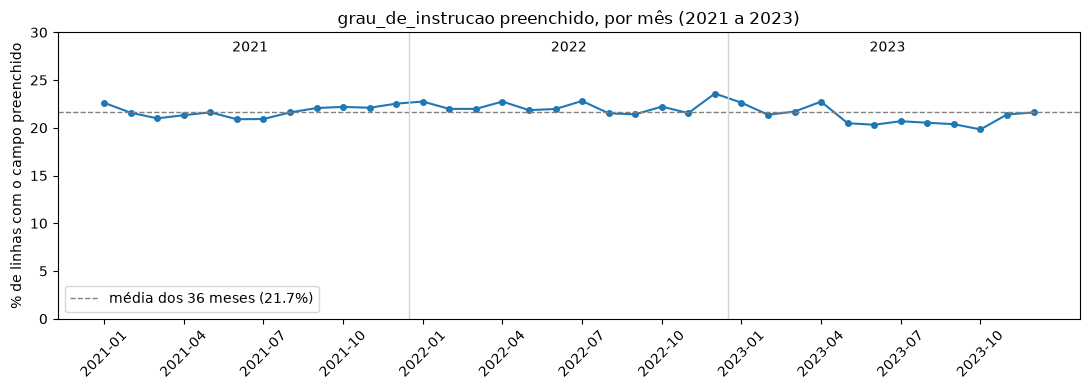

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))
x = range(len(mensal))
ax.plot(x, pct, marker="o", linewidth=1.5, markersize=4)
ax.axhline(pct.mean(), linestyle="--", linewidth=1, color="gray", label=f"média dos 36 meses ({pct.mean():.1f}%)")
for corte in (11.5, 23.5):
    ax.axvline(corte, color="lightgray", linewidth=1)
for i, ano in enumerate(ANOS):
    ax.text(i * 12 + 5.5, 28, str(ano), ha="center")
ax.set_ylim(0, 30)
ax.set_xticks(range(0, len(mensal), 3))
ax.set_xticklabels(mensal["mes"][::3], rotation=45)
ax.set_ylabel("% de linhas com o campo preenchido")
ax.set_title("grau_de_instrucao preenchido, por mês (2021 a 2023)")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(EVIDENCIAS / "grau_instrucao_36_meses.png", dpi=150)
plt.show()

### 6.1 Preenchimento por tipo de vítima

In [17]:
print("preenchidos de mensal.csv == preenchidos dos perfis:",
      list(mensal_res.groupby("ano")["grau_preenchido"].sum()) == list(por_ano["preenchidos"]))

vit = dimensao[dimensao["dimensao"] == "tipo_de_vitima"].set_index(["valor", "ano"])
linhas_v = vit["linhas"].unstack("ano")
grau_v = vit["grau_preenchido"].unstack("ano")

print("\n% de linhas com grau_de_instrucao preenchido, por tipo de vítima:")
display((grau_v / linhas_v * 100).round(1))

print("condutores: % das linhas | % dos valores preenchidos")
pd.DataFrame({
    "% das linhas": (linhas_v.loc["CONDUTOR"] / linhas_v.sum() * 100).round(1),
    "% dos preenchidos": (grau_v.loc["CONDUTOR"] / grau_v.sum() * 100).round(1),
})

preenchidos de mensal.csv == preenchidos dos perfis: True

% de linhas com grau_de_instrucao preenchido, por tipo de vítima:


ano,2021,2022,2023
valor,,,
CONDUTOR,1.2,1.3,1.2
NAO DISPONIVEL,32.9,37.1,28.8
PASSAGEIRO,35.5,34.9,34.8
PEDESTRE,82.2,82.6,82.8


condutores: % das linhas | % dos valores preenchidos


,% das linhas,% dos preenchidos
ano,,
2021,46.7,2.6
2022,47.3,2.8
2023,46.1,2.6


## 7. Achado 4 · Nulos e `NAO DISPONIVEL` por ano

Dois tipos de "sem informação": o nulo de verdade (campo vazio) e o texto `NAO DISPONIVEL`, que o pandas não conta como nulo. Primeiro por ano (perfis), depois por mês, região, tipo de via e tipo de vítima (resumos).

In [18]:
nulos = pd.concat([tabela(a, "2.").set_index("coluna")["% nulos"].rename(a) for a in ANOS], axis=1)
nulos = nulos[(nulos > 0).any(axis=1)].copy()
nulos["dif 2022→2023 (pp)"] = (nulos[2023] - nulos[2022]).round(2)
nulos

,2021,2022,2023,dif 2022→2023 (pp)
coluna,,,,
id_veiculo,21.21,20.09,21.77,1.68
tipo_veiculo_vitima,21.16,20.02,21.73,1.71
modo_transporte_vitima,20.77,19.54,21.29,1.75
idade,1.33,1.43,0.40,-1.03
profissao,10.32,9.32,12.20,2.88
grau_de_instrucao,78.29,77.82,78.91,1.09
nacionalidade,11.94,10.44,13.13,2.69
data_obito,98.14,97.95,98.04,0.09
ano_obito,98.14,97.95,98.04,0.09


In [19]:
def serie_valor(col: str, valor: str, campo: str) -> dict:
    return {a: tabela(a, col, -1).set_index("valor").loc[valor, campo] for a in ANOS}

colunas_nd = ["tipo_de_vitima", "gravidade_lesao", "local_via", "sexo", "tipo_via", "tipo_veiculo_vitima", "local_obito"]
nd_pct = pd.DataFrame({c: serie_valor(c, "NAO DISPONIVEL", "%") for c in colunas_nd}).T
nd_n   = pd.DataFrame({c: serie_valor(c, "NAO DISPONIVEL", "n") for c in colunas_nd}).T
print("% de linhas com NAO DISPONIVEL:")
display(nd_pct)
print("número de linhas com NAO DISPONIVEL:")
nd_n

% de linhas com NAO DISPONIVEL:


,2021,2022,2023
tipo_de_vitima,14.27,12.56,15.07
gravidade_lesao,9.03,7.15,9.91
local_via,7.99,8.04,26.81
sexo,1.34,0.11,0.21
tipo_via,0.12,0.13,0.11
tipo_veiculo_vitima,0.06,0.06,0.05
local_obito,0.01,0.02,0.01


número de linhas com NAO DISPONIVEL:


,2021,2022,2023
tipo_de_vitima,37232,33414,42182
gravidade_lesao,23548,19027,27739
local_via,20842,21389,75067
sexo,3487,289,590
tipo_via,326,350,297
tipo_veiculo_vitima,164,166,150
local_obito,26,54,25


In [20]:
lv = pd.concat([tabela(a, "local_via", -1).set_index("valor")["n"].rename(a) for a in ANOS], axis=1)
print("local_via, número de linhas:")
display(lv)
print("local_via, % das linhas:")
display((lv / lv.sum() * 100).round(2))
print("aumento de NAO DISPONIVEL em local_via, 2022→2023:", lv.loc["NAO DISPONIVEL", 2023] - lv.loc["NAO DISPONIVEL", 2022], "linhas")

local_via, número de linhas:


,2021,2022,2023
valor,,,
PUBLICO,235586,239837,199603
NAO DISPONIVEL,20842,21389,75067
(nulo),3041,3381,3856
PRIVADO,1417,1521,1437


local_via, % das linhas:


,2021,2022,2023
valor,,,
PUBLICO,90.30,90.12,71.30
NAO DISPONIVEL,7.99,8.04,26.81
(nulo),1.17,1.27,1.38
PRIVADO,0.54,0.57,0.51


aumento de NAO DISPONIVEL em local_via, 2022→2023: 53678 linhas


### 7.1 Mês a mês: `local_via` e `sexo`

In [21]:
m = mensal_res.copy()
m["local_via_nd_%"] = (m["local_via_nd"] / m["linhas"] * 100).round(2)
m["sexo_nd_%"] = (m["sexo_nd"] / m["linhas"] * 100).round(2)
pivo = m.pivot(index="mes", columns="ano", values=["local_via_nd_%", "sexo_nd_%"])
print("% de local_via = NAO DISPONIVEL, por mês:")
display(pivo["local_via_nd_%"])
print("% de sexo = NAO DISPONIVEL, por mês:")
pivo["sexo_nd_%"]

% de local_via = NAO DISPONIVEL, por mês:


ano,2021,2022,2023
mes,,,
01,8.18,8.61,9.22
02,7.73,8.14,8.53
03,8.07,8.00,8.42
04,8.15,8.07,11.40
05,8.07,7.95,32.61
06,7.80,7.78,37.69
07,7.91,7.56,38.53
08,7.95,8.12,25.01
09,8.24,8.93,37.26


% de sexo = NAO DISPONIVEL, por mês:


ano,2021,2022,2023
mes,,,
01,1.31,0.06,0.10
02,1.30,0.14,0.15
03,1.51,0.09,0.19
04,1.44,0.12,0.18
05,1.35,0.09,0.16
06,1.41,0.13,0.19
07,1.41,0.13,0.28
08,1.19,0.12,0.25
09,1.48,0.10,0.20


### 7.2 Onde está o aumento de `local_via` em 2023

In [22]:
reg = dimensao[dimensao["dimensao"] == "regiao_administrativa"].copy()
reg["pct"] = reg["local_via_nd"] / reg["linhas"] * 100
por_reg = reg.pivot(index="valor", columns="ano", values="pct").round(1)
por_reg["dif 2022→2023 (pp)"] = (por_reg[2023] - por_reg[2022]).round(1)
print("% de local_via = NAO DISPONIVEL por região (todas as regiões sobem em 2023):")
por_reg.sort_values("dif 2022→2023 (pp)", ascending=False)

% de local_via = NAO DISPONIVEL por região (todas as regiões sobem em 2023):


ano,2021,2022,2023,dif 2022→2023 (pp)
valor,,,,
ARAÇATUBA,11.9,12.6,45.0,32.4
PRESIDENTE PRUDENTE,8.7,12.4,43.9,31.5
METROPOLITANA DE SÃO PAULO,9.3,8.1,31.3,23.2
BARRETOS,4.1,5.4,24.0,18.6
CENTRAL,6.7,8.8,26.5,17.7
SÃO JOSÉ DOS CAMPOS,10.0,9.2,26.5,17.3
MARÍLIA,6.6,7.0,23.3,16.3
CAMPINAS,6.4,8.3,24.6,16.3
SÃO JOSÉ DO RIO PRETO,7.6,6.2,22.1,15.9


In [23]:
for dim, titulo in [("tipo_via", "tipo de via"), ("tipo_de_vitima", "tipo de vítima")]:
    t = dimensao[dimensao["dimensao"] == dim].copy()
    t["pct"] = (t["local_via_nd"] / t["linhas"] * 100).round(1)
    print(f"% de local_via = NAO DISPONIVEL por {titulo}:")
    display(t.pivot(index="valor", columns="ano", values="pct"))

via = dimensao[dimensao["dimensao"] == "tipo_via"].pivot(index="valor", columns="ano", values="local_via_nd")
aumento = via[2023].sum() - via[2022].sum()
print("aumento de NAO DISPONIVEL em local_via, 2022→2023:", aumento, "linhas |",
      f"vias urbanas respondem por {(via.loc['VIAS URBANAS', 2023] - via.loc['VIAS URBANAS', 2022]) / aumento * 100:.0f}%")

% de local_via = NAO DISPONIVEL por tipo de via:


ano,2021,2022,2023
valor,,,
ESTRADAS E RODOVIAS,5.0,5.6,10.4
NAO DISPONIVEL,85.9,58.3,60.3
VIAS URBANAS,8.4,8.5,30.1


% de local_via = NAO DISPONIVEL por tipo de vítima:


ano,2021,2022,2023
valor,,,
CONDUTOR,4.6,4.9,19.8
NAO DISPONIVEL,30.8,33.8,57.4
PASSAGEIRO,3.6,3.8,23.0
PEDESTRE,4.1,3.5,24.9


aumento de NAO DISPONIVEL em local_via, 2022→2023: 53678 linhas | vias urbanas respondem por 96%


### 7.3 Onde está o `NAO DISPONIVEL` de `sexo`

In [24]:
sx = dimensao[dimensao["dimensao"] == "tipo_via"].pivot(index="valor", columns="ano", values="sexo_nd")
print("linhas com sexo = NAO DISPONIVEL, por tipo de via:")
display(sx)
print("vias urbanas, % do total de sexo NAO DISPONIVEL em 2021:", round(sx.loc["VIAS URBANAS", 2021] / sx[2021].sum() * 100, 1))
print("estradas e rodovias, % do total em 2022 e 2023:",
      [float(round(sx.loc["ESTRADAS E RODOVIAS", a] / sx[a].sum() * 100, 1)) for a in (2022, 2023)])

linhas com sexo = NAO DISPONIVEL, por tipo de via:


ano,2021,2022,2023
valor,,,
ESTRADAS E RODOVIAS,904,267,564
NAO DISPONIVEL,0,1,0
VIAS URBANAS,2583,21,26


vias urbanas, % do total de sexo NAO DISPONIVEL em 2021: 74.1
estradas e rodovias, % do total em 2022 e 2023: [92.4, 95.6]


## 8. Achado 5 · Texto e valores corrompidos

Os três `corrompidos_AAAA.csv` (listas da célula de valores corrompidos de cada perfil) e a pergunta 4 de cada perfil (espaços sobrando).

In [25]:
corr = {a: pd.read_csv(PERFIS / f"corrompidos_{a}.csv") for a in ANOS}
conj = {a: set(zip(c["coluna"], c["valor"])) for a, c in corr.items()}

print("valores por ano:", {a: len(c) for a, c in corr.items()})
print("mesmos valores nos 3 anos:", conj[2021] == conj[2022] == conj[2023])
print("colunas afetadas:", sorted({col for col, _ in conj[2021]}))
sorted(valor for _, valor in conj[2021])

valores por ano: {2021: 8, 2022: 8, 2023: 8}
mesmos valores nos 3 anos: True
colunas afetadas: ['municipio']


['APARECIDA D OESTE',
 'ESTRELA D OESTE',
 'GUARANI D OESTE',
 'PALMEIRA D OESTE',
 'SANTA BARBARA D OESTE',
 'SANTA CLARA D OESTE',
 'SANTA RITA D OESTE',
 'SAO JOAO DO PAU D ALHO']

In [26]:
p4 = pd.concat([tabela(a, "4.", 0).assign(ano=a) for a in ANOS], ignore_index=True)
p4[["ano", "coluna", "motivo", "valores distintos", "linhas"]]

,ano,coluna,motivo,valores distintos,linhas
0,2021,profissao,espaco_duplo,1,1
1,2021,nacionalidade,espaco_nas_pontas,65,229731
2,2022,nacionalidade,espaco_nas_pontas,68,238353
3,2023,profissao,letra_isolada,1,1
4,2023,nacionalidade,espaco_nas_pontas,74,243207


## 9. Resumo

**O que foi feito:** comparação dos perfis de 2021, 2022 e 2023 (ETL-07, 08 e 09) e de três resumos gerados do `01_bruto.parquet`: linhas, nulos, categorias que surgiram ou sumiram e o preenchimento de `grau_de_instrucao` nos 36 meses. Nenhum dado foi alterado.

**Por quê:** as regras de limpeza (ETL-14, 15, 16 e 17) e as dimensões (ETL-19 a 22) vão rodar nos três anos de uma vez. Era preciso saber se a base se comporta igual nos três anos ou se algum ano pede tratamento próprio.

**Resultados (5 achados):**
1. **Estrutura igual, volume maior.** As 31 colunas, na mesma ordem, aparecem nos três anos. As linhas passam de 260.886 para 266.128 (+2,0%) e 279.963 (+5,2%), 806.977 no total. Os óbitos somam 15.793, sempre iguais a `gravidade_lesao` = FATAL.
2. **Nenhuma categoria relevante surgiu ou sumiu.** O conjunto de valores das seis colunas de domínio é idêntico nos três anos. A união tem os 645 municípios (os que faltam em algum ano têm de 2 a 8 linhas) e 90 nacionalidades, das quais 38 raras (1 a 4 linhas por ano). O aumento de `profissao` (515, 588 e 658 valores) vem de grafia: valores em caixa mista passam de 0,00% das linhas em 2021 para 0,19% em 2022 e 1,05% em 2023, e depois de normalizar o número fica estável (504, 482 e 485).
3. **`grau_de_instrucao` não muda ao longo dos 36 meses, e o nulo depende do tipo de vítima.** Fica preenchido em cerca de 22% das linhas em todos os meses (de 19,83% a 23,59%). Por tipo de vítima: pedestres ~82%, passageiros ~35%, condutores ~1,2%, nos três anos. Não existe período confiável.
4. **`NAO DISPONIVEL` muda em datas precisas.** `local_via` vai de ~8% para 25% a 38% a partir de mai/2023, em todas as regiões e tipos de vítima, e 96% do aumento está em vias urbanas. `sexo` cai de 1,39% em dez/2021 para 0,06% em jan/2022, saindo das vias urbanas.
5. **O texto tem os mesmos defeitos nos três anos.** Os três `corrompidos_AAAA.csv` listam exatamente os mesmos 8 municípios (apóstrofo trocado por espaço). `nacionalidade` tem espaços no fim em todos os valores, nos três anos.